In [ ]:
import re
import string
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud

import nltk
from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from sklearn.utils import resample

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

warnings.filterwarnings("ignore")

nltk.download("stopwords")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [ ]:
df = pd.read_csv("/content/Dataset---Hate-Speech-Detection-using-Deep-Learning.csv")

df.head()

,class,tweet
0,2,!!! RT @mayasolovely: As a woman you shouldn't...
1,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...
2,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...
3,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...
4,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...


In [ ]:
print("Dataset Shape :", df.shape)

print("\nColumns")
print(df.columns)

print("\nMissing Values")
print(df.isnull().sum())

print("\nClass Distribution")
print(df["class"].value_counts())

df.info()

Dataset Shape : (24783, 2)

Columns
Index(['class', 'tweet'], dtype='object')

Missing Values
class    0
tweet    0
dtype: int64

Class Distribution
class
1    19190
2     4163
0     1430
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24783 entries, 0 to 24782
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   class   24783 non-null  int64 
 1   tweet   24783 non-null  object
dtypes: int64(1), object(1)
memory usage: 387.4+ KB


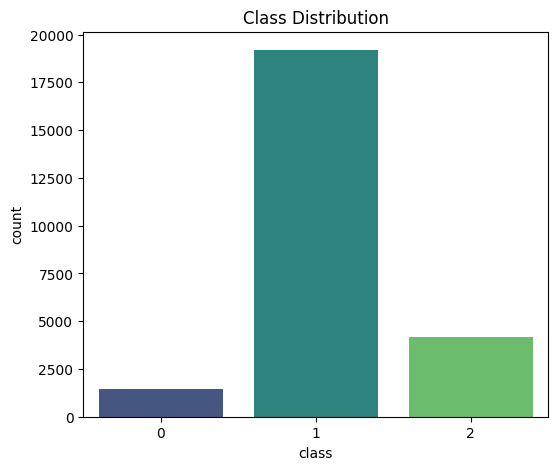

In [ ]:
plt.figure(figsize=(6,5))

sns.countplot(
    x="class",
    data=df,
    palette="viridis"
)

plt.title("Class Distribution")
plt.show()

In [ ]:
label_map = {
    0: "Hate Speech",
    1: "Offensive Language",
    2: "Neither"
}

df["label"] = df["class"].map(label_map)

df.head()

,class,tweet,label
0,2,!!! RT @mayasolovely: As a woman you shouldn't...,Neither
1,1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...,Offensive Language
2,1,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...,Offensive Language
3,1,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...,Offensive Language
4,1,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...,Offensive Language


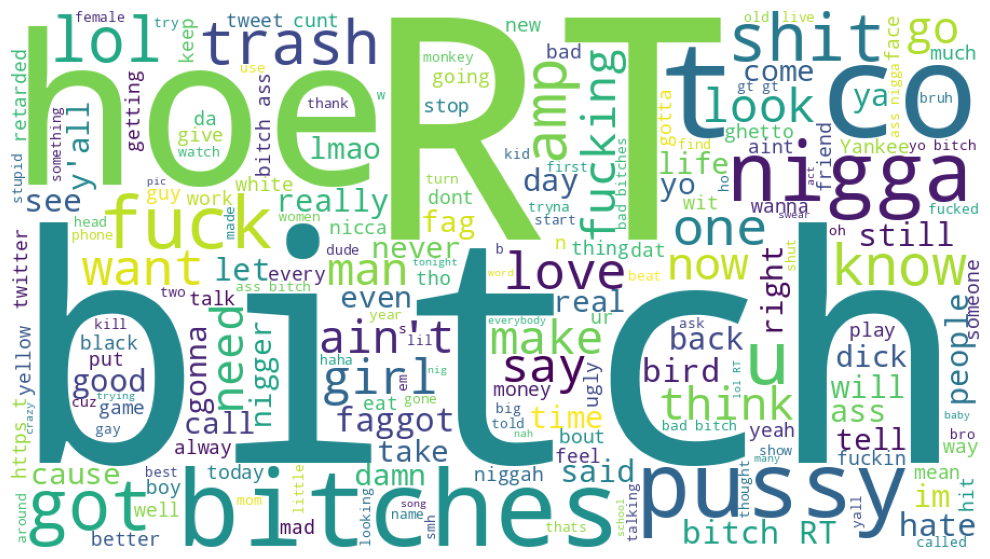

In [ ]:
text = " ".join(df["tweet"])

wordcloud = WordCloud(
    width=900,
    height=500,
    background_color="white"
).generate(text)

plt.figure(figsize=(14,7))
plt.imshow(wordcloud)
plt.axis("off")
plt.show()

In [ ]:
stop_words = set(stopwords.words("english"))

def clean_text(text):

    text = str(text).lower()

    text = re.sub(r"http\S+", "", text)

    text = re.sub(r"www\S+", "", text)

    text = re.sub(r"@\w+", "", text)

    text = re.sub(r"#", "", text)

    text = re.sub(r"\d+", "", text)

    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )

    words = text.split()

    words = [
        word
        for word in words
        if word not in stop_words
    ]

    return " ".join(words)

In [ ]:
df["clean_tweet"] = df["tweet"].apply(clean_text)

df[
    ["tweet","clean_tweet"]
].head()

,tweet,clean_tweet
0,!!! RT @mayasolovely: As a woman you shouldn't...,rt woman shouldnt complain cleaning house amp ...
1,!!!!! RT @mleew17: boy dats cold...tyga dwn ba...,rt boy dats coldtyga dwn bad cuffin dat hoe st...
2,!!!!!!! RT @UrKindOfBrand Dawg!!!! RT @80sbaby...,rt dawg rt ever fuck bitch start cry confused ...
3,!!!!!!!!! RT @C_G_Anderson: @viva_based she lo...,rt look like tranny
4,!!!!!!!!!!!!! RT @ShenikaRoberts: The shit you...,rt shit hear might true might faker bitch told ya


In [ ]:
# Check class distribution
print(df["class"].value_counts())

# Separate each class
class_0 = df[df["class"] == 0]
class_1 = df[df["class"] == 1]
class_2 = df[df["class"] == 2]

# Use the largest class as reference
max_size = max(len(class_0), len(class_1), len(class_2))

# Oversample minority classes
class_0 = resample(
    class_0,
    replace=True,
    n_samples=max_size,
    random_state=42
)

class_1 = resample(
    class_1,
    replace=True,
    n_samples=max_size,
    random_state=42
)

class_2 = resample(
    class_2,
    replace=True,
    n_samples=max_size,
    random_state=42
)

# Combine and shuffle
balanced_df = pd.concat([class_0, class_1, class_2])

balanced_df = balanced_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print(balanced_df["class"].value_counts())

class
1    19190
2     4163
0     1430
Name: count, dtype: int64
class
1    19190
2    19190
0    19190
Name: count, dtype: int64


In [ ]:
X = balanced_df["clean_tweet"]

y = balanced_df["class"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples :", len(X_train))
print("Testing Samples  :", len(X_test))

Training Samples : 46056
Testing Samples  : 11514


In [ ]:
max_words = 10000
max_len = 100

tokenizer = Tokenizer(
    num_words=max_words,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

word_index = tokenizer.word_index

print("Vocabulary Size:", len(word_index))

Vocabulary Size: 17630


In [ ]:
X_train_seq = tokenizer.texts_to_sequences(X_train)

X_test_seq = tokenizer.texts_to_sequences(X_test)

In [ ]:
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

print(X_train_pad.shape)
print(X_test_pad.shape)

(46056, 100)
(11514, 100)


In [ ]:
model = keras.Sequential([

    layers.Embedding(
        input_dim=max_words,
        output_dim=128,
        input_length=max_len
    ),

    layers.Bidirectional(
        layers.LSTM(
            64,
            dropout=0.3,
            recurrent_dropout=0.3
        )
    ),

    layers.Dense(
        64,
        activation="relu"
    ),

    layers.Dropout(0.5),

    layers.Dense(
        3,
        activation="softmax"
    )

])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [16]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [17]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    verbose=1
)

checkpoint = keras.callbacks.ModelCheckpoint(
    "best_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    verbose=1
)

In [18]:
history = model.fit(

    X_train_pad,

    y_train,

    validation_split=0.2,

    epochs=15,

    batch_size=64,

    callbacks=[
        early_stop,
        reduce_lr,
        checkpoint
    ],

    verbose=1

)

Epoch 1/15
576/576 ━━━━━━━━━━━━━━━━━━━━ 0s 304ms/step - accuracy: 0.7088 - loss: 0.6346
Epoch 1: val_accuracy improved from None to 0.94746, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
576/576 ━━━━━━━━━━━━━━━━━━━━ 194s 321ms/step - accuracy: 0.8447 - loss: 0.3909 - val_accuracy: 0.9475 - val_loss: 0.1592 - learning_rate: 0.0010
Epoch 2/15
576/576 ━━━━━━━━━━━━━━━━━━━━ 0s 311ms/step - accuracy: 0.9553 - loss: 0.1421
Epoch 2: val_accuracy improved from 0.94746 to 0.96081, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
576/576 ━━━━━━━━━━━━━━━━━━━━ 206s 329ms/step - accuracy: 0.9586 - loss: 0.1328 - val_accuracy: 0.9608 - val_loss: 0.1181 - learning_rate: 0.0010
Epoch 3/15
576/576 ━━━━━━━━━━━━━━━━━━━━ 0s 310ms/step - accuracy: 0.9739 - loss: 0.0850
Epoch 3: val_accuracy improved from 0.96081 to 0.96667, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
576/576 ━━━━━━━━━━━━━━━━━━

In [19]:
# Evaluate on the test set
test_loss, test_accuracy = model.evaluate(X_test_pad, y_test, verbose=1)

print(f"\nTest Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")

360/360 ━━━━━━━━━━━━━━━━━━━━ 16s 44ms/step - accuracy: 0.9738 - loss: 0.0959

Test Loss     : 0.0959
Test Accuracy : 0.9738


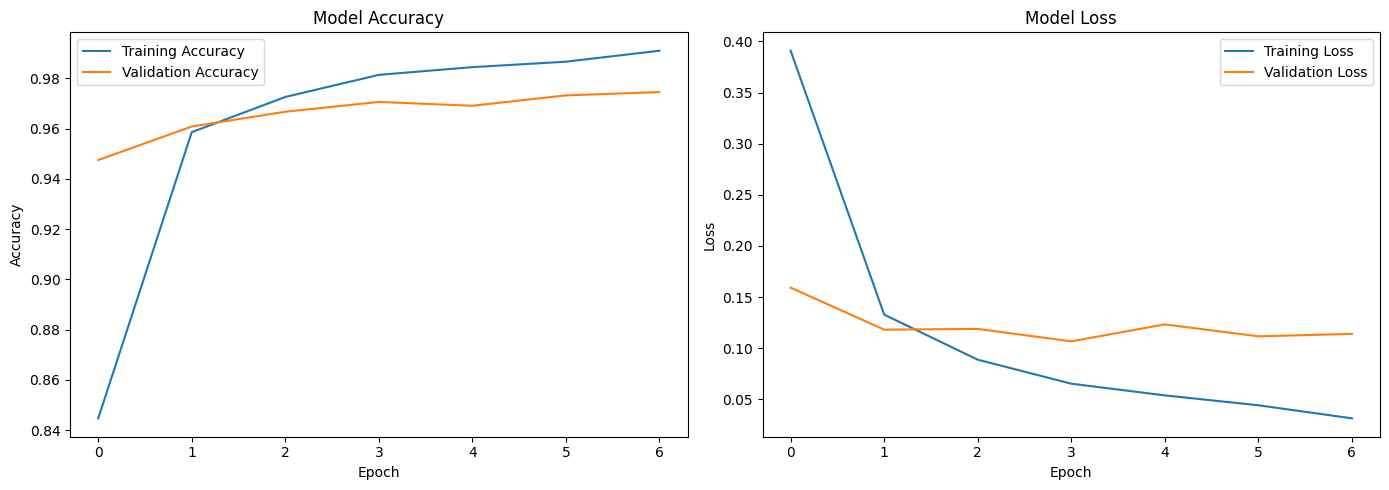

In [20]:
plt.figure(figsize=(14,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1,2,2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [21]:
# Predict probabilities
y_pred_prob = model.predict(X_test_pad)

# Convert probabilities into class labels
y_pred = np.argmax(y_pred_prob, axis=1)

print("Prediction Shape :", y_pred.shape)

360/360 ━━━━━━━━━━━━━━━━━━━━ 17s 46ms/step
Prediction Shape : (11514,)


In [22]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Hate Speech",
            "Offensive Language",
            "Neither"
        ]
    )
)

                    precision    recall  f1-score   support

       Hate Speech       0.96      0.99      0.98      3838
Offensive Language       0.98      0.95      0.96      3838
           Neither       0.98      0.98      0.98      3838

          accuracy                           0.97     11514
         macro avg       0.97      0.97      0.97     11514
      weighted avg       0.97      0.97      0.97     11514



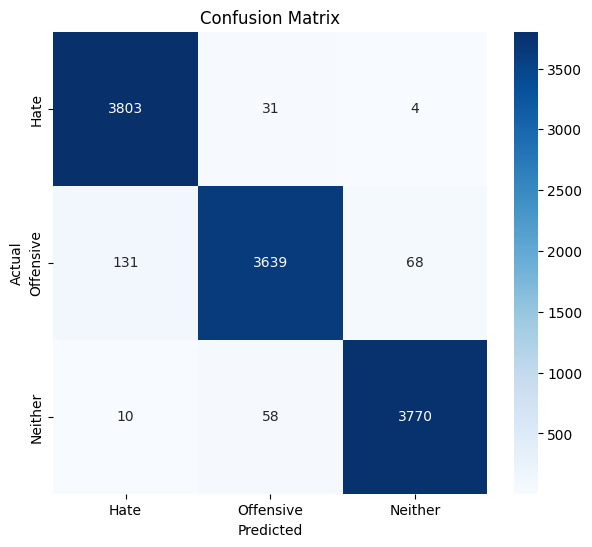

In [23]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Hate",
        "Offensive",
        "Neither"
    ],
    yticklabels=[
        "Hate",
        "Offensive",
        "Neither"
    ]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [31]:
import gradio as gr

description = """
## Hate Speech Detection using BiLSTM

This model classifies text into one of the following categories:

• Hate Speech
• Offensive Language
• Neither

Simply type a sentence below and click Predict.
"""

with gr.Blocks(theme=gr.themes.Soft()) as demo:

    gr.Markdown("# 🛡️ Hate Speech Detection")

    gr.Markdown(description)

    input_text = gr.Textbox(
        label="Enter Text",
        placeholder="Type your sentence here...",
        lines=5
    )

    output = gr.Label(
        num_top_classes=3,
        label="Prediction"
    )

    predict_button = gr.Button(
        "Predict",
        variant="primary"
    )

    clear_button = gr.ClearButton(
        components=[input_text, output]
    )

    predict_button.click(
        fn=predict_text,
        inputs=input_text,
        outputs=output
    )

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b04c41bf509e616d39.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
